<a href="https://colab.research.google.com/github/akshin-kuvshin/numerical-methods/blob/main/lab4/lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №4. Аппроксимация данных методом наименьших квадратов

## Выполнил: Данила Аксёнов, гр. 932420

## Вариант: 1

In [117]:
import numpy as np
from matplotlib import pyplot as plt
print('Setup completed')

Setup completed


### Исходные данные:

In [118]:
x = np.array([0.35, 0.48, 0.97, 1.08, 1.18, 1.35])
y = np.array([1.419, 1.616, 2.637, 2.944, 3.254, 4.119])
n = len(x) # == len(y)

In [119]:
def plot_nodes(color='black'):
    for x_i, y_i in zip(x, y):
        plt.plot(x_i, y_i, marker='x', color=color)

## **Задание 8**

* Аппроксимировать заданные значения $ (x_i, y_i) $ методов наименьших квадратов, используя алгебраический многочлен третьей степени;
* Вывести матрицу Грама;
* Построить графики аппроксимирующего многочлена и исходных данных.

### Решение:

In [120]:
m = 3 # степень аппроксимирующего многочлена
m

3

Матрица Грама:

In [121]:
A = np.zeros((m + 1, m + 1)) # матрица Грама (матрица коэффициентов системы)
for i in range(m + 1):
    for j in range(m + 1):
        A[i][j] = np.sum(x ** (i + j))
A

array([[ 6.        ,  5.41      ,  5.6751    ,  6.429259  ],
       [ 5.41      ,  5.6751    ,  6.429259  ,  7.57415619],
       [ 5.6751    ,  6.429259  ,  7.57415619,  9.13058588],
       [ 6.429259  ,  7.57415619,  9.13058588, 11.18691448]])

In [122]:
b = np.zeros(m + 1) # вектор свободных членов системы
for i in range(m + 1):
    b[i] = np.sum((x ** i) * y)
b

array([15.989     , 16.41011   , 18.4989359 , 21.83557788])

In [123]:
c_lsm = np.linalg.solve(A, b) # коэффициенты аппроксимирующего многочлена
c_lsm

array([ 0.50813067,  3.46239359, -3.2534814 ,  1.9710668 ])

In [124]:
def f_lsm(x0):
    y0 = 0
    for i in range(m + 1):
        y0 += c_lsm[i] * (x0 ** i)
    return y0

In [125]:
def plot_lsm(num=100, d=0., color='#0072B2'):
    x_ = np.linspace(x[0] - d, x[-1] + d, num=num)
    y_ = np.array(list(map(f_lsm, x_)))
    plt.plot(x_, y_, color=color)

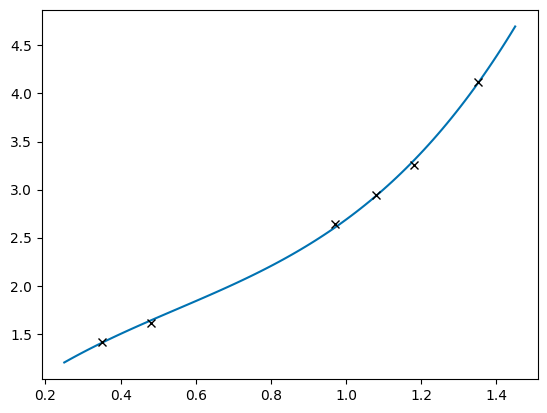

In [126]:
plot_lsm(d=0.1)
plot_nodes()
plt.show()

## **Задание 9**

* Аппроксимировать заданные значения $ (x_i, y_i) $ методов наименьших квадратов, используя многочлен третьей степени с использованием ортогональных полиномов Чебышева дискретной переменной;
* Вывести матрицу Грама;
* Построить графики аппроксимирующего многочлена и исходных данных.

In [127]:
t = [] # здесь будем хранить построенные ортогональные полиномы Чебышева дискретной переменной
v = [] # здесь будем хранить значения построенных полиномов в узлах интерполяции
t.append(lambda z: np.ones_like(z, dtype=float)) # t_0
v.append(t[0](x))
mu = x.mean()
t.append(lambda z, mu=mu: z - mu) # t_1
v.append(t[1](x))
# здесь x.mean() - среднее арифметическое значений x_i, чем и является коэффициент a_1_1 (из учебника)

# построим теперь t_2 и t_3 с помощью двухслойной рекуррентной формулы:
for i in [2, 3]:
    s1 = np.sum(x * (v[i - 1] ** 2))
    s2 = np.sum(v[i - 1] ** 2)
    s3 = np.sum(v[i - 2] ** 2)
    a = s1 / s2
    b = s2 / s3
    t.append(lambda z, t1=t[i - 1], t2=t[i - 2], a=a, b=b: (z - a) * t1(z) - b * t2(z))
    v.append(t[i](x))

In [128]:
# коэффициенты аппроксимации перед полиномами Чебышева
c_cheb = np.array([np.sum(y * v[i]) / np.sum(v[i] ** 2) for i in range(m + 1)])
c_cheb

array([2.66483333, 2.50081965, 2.04131968, 1.9710668 ])

In [129]:
def f_cheb(x0):
    y0 = 0
    for i in range(m + 1):
        y0 += c_cheb[i] * t[i](x0)
    return y0

In [130]:
def plot_cheb(num=100, d=0., color='#E69F00'):
    x_ = np.linspace(x[0] - d, x[-1] + d, num=num)
    y_ = np.array(list(map(f_cheb, x_)))
    plt.plot(x_, y_, color=color)

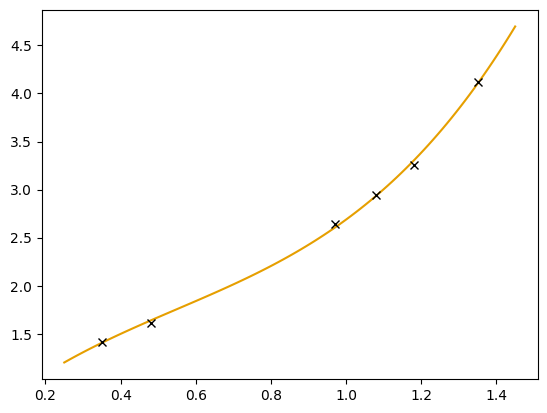

In [131]:
plot_cheb(d=0.1)
plot_nodes()
plt.show()